# Review-Based Extractive Question Answering using LoRA

## Overview

This project fine-tunes a pre-trained DistilBERT model for extractive Question Answering (QA) using Low-Rank Adaptation (LoRA).

In extractive Question Answering, the model receives a question and a passage and predicts the start and end positions of the answer within that passage.

The model does not generate a new answer. Instead, it extracts the answer directly from the given context.

### Example

**Question:**

How is the battery?

**Context:**

I love the display. The battery lasts around 12 hours on a single charge. The keyboard feels cheap.

**Extracted Answer:**

the battery lasts around 12 hours on a single charge

---

## Dataset

The dataset contains question-passage pairs collected from customer reviews across multiple domains.

The dataset contains the following columns:

| Column | Description |
|---|---|
| `question` | Question about the review |
| `context` | Customer review passage |
| `answer_text` | Correct answer extracted from the context |
| `answer_start` | Character-level starting position of the answer |
| `domain` | Review domain |

---

## Objective

The objective is to fine-tune:

`distilbert-base-uncased`

for extractive Question Answering using:

- Hugging Face Transformers
- PEFT
- LoRA
- PyTorch
- Hugging Face Trainer

The final model must predict:

- `start_logits`
- `end_logits`

for each question-context pair.

---

## Project Pipeline

The project follows this pipeline:

1. Load the dataset
2. Explore the dataset
3. Validate answer positions
4. Split the dataset
5. Load the DistilBERT tokenizer
6. Tokenize questions and contexts
7. Convert character-level answer positions into token-level positions
8. Load DistilBERT for Question Answering
9. Apply LoRA using PEFT
10. Fine-tune using Hugging Face Trainer
11. Evaluate the model
12. Calculate Token F1
13. Test the model on unseen examples

---

## Why LoRA?

Full fine-tuning updates all parameters of DistilBERT.

LoRA instead trains a small number of additional parameters while keeping most of the pre-trained model frozen.

This provides:

- Fewer trainable parameters
- Lower memory usage
- Faster training
- Efficient fine-tuning
- Better suitability for Apple Silicon hardware

---

## Hardware

This project is developed and trained on:

**Apple Silicon MacBook**

PyTorch will automatically use Apple's Metal Performance Shaders (MPS) backend when available.

The implementation does not require CUDA.

In [1]:
# Run this cell before writing your solution
import urllib.request
import pandas as pd
import numpy as np
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForQuestionAnswering,
    TrainingArguments,
    Trainer,
    DefaultDataCollator
)
from peft import LoraConfig, get_peft_model, TaskType
from datasets import Dataset

urllib.request.urlretrieve("https://s3.ap-south-1.amazonaws.com/new-assets.ccbp.in/frontend/content/aiml/subjqa_dataset.csv", "subjqa_dataset.csv")

df = pd.read_csv("subjqa_dataset.csv")
df = df.dropna(subset=["question", "context", "answer_text"]).reset_index(drop=True)
print(f"Total QA pairs: {len(df)}")
print(f"Domains: {df['domain'].unique().tolist()}")

Total QA pairs: 1500
Domains: ['books', 'electronics', 'grocery', 'movies', 'restaurants', 'tripadvisor']


## Imports and Mac Device Setup

In [2]:
import os
import random
import urllib.request

import numpy as np
import pandas as pd
import torch

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForQuestionAnswering,
    TrainingArguments,
    Trainer,
    DefaultDataCollator
)

from peft import (
    LoraConfig,
    get_peft_model,
    TaskType
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Detect Apple Silicon MPS
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Selected device:", device)
print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.0
Selected device: mps
MPS available: True
CUDA available: False


##  Download and Load Dataset

In [3]:
DATA_URL = (
    "https://s3.ap-south-1.amazonaws.com/"
    "new-assets.ccbp.in/frontend/content/aiml/subjqa_dataset.csv"
)

DATA_PATH = "subjqa_dataset.csv"

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)

df = df.dropna(
    subset=[
        "question",
        "context",
        "answer_text",
        "answer_start"
    ]
).reset_index(drop=True)

print(f"Total QA pairs: {len(df)}")
print(f"Columns: {df.columns.tolist()}")
print(f"Domains: {df['domain'].unique().tolist()}")

Total QA pairs: 1500
Columns: ['question', 'context', 'answer_text', 'answer_start', 'domain']
Domains: ['books', 'electronics', 'grocery', 'movies', 'restaurants', 'tripadvisor']


## Dataset Inspection

In [4]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDomain Distribution:")
print(df["domain"].value_counts())

print("\nFirst Sample:")
print("=" * 80)

sample = df.iloc[0]

print("Question:")
print(sample["question"])

print("\nContext:")
print(sample["context"])

print("\nAnswer:")
print(sample["answer_text"])

print("\nAnswer Start:")
print(sample["answer_start"])

Dataset Shape: (1500, 5)

Missing Values:
question        0
context         0
answer_text     0
answer_start    0
domain          0
dtype: int64

Domain Distribution:
domain
books          250
electronics    250
grocery        250
movies         250
restaurants    250
tripadvisor    250
Name: count, dtype: int64

First Sample:
Question:
Is it a good character?

Context:
I keep thinking the stories for this group of friends couldn't possibly get any better. Any more involved it beautiful. And each time I eat my words! Don't ever ask me to pick a favorite bc I don't think I can. I love this series. I love that each one is so completely full of drama you find yourself wondering if love can conquer all. Can these people possibly make it out of these scenarios alive, unscathed. Just when you think there's no way out, your kicked back and realize you were wrong all along. I'm so glad Cain finally found his happiness. I'm so glad he finally found love. I found myself pulling for him from book

## Answer Span Validation

The dataset provides the answer location using `answer_start`, which is a character-level index into the context.

Before tokenization, we verify that:

`context[answer_start : answer_start + len(answer_text)]`

exactly matches `answer_text`.

This validation is important because the Question Answering model will eventually need token-level start and end labels derived from these character positions.

If the character-level labels are incorrect, the resulting token-level labels would also be incorrect.

In [5]:
def validate_answer_span(row):
    context = row["context"]
    answer = row["answer_text"]
    start = int(row["answer_start"])
    
    extracted = context[start:start + len(answer)]
    
    return extracted == answer


df["span_valid"] = df.apply(validate_answer_span, axis=1)

valid_count = df["span_valid"].sum()
invalid_count = (~df["span_valid"]).sum()

print("Total samples :", len(df))
print("Valid spans   :", valid_count)
print("Invalid spans :", invalid_count)
print("Valid ratio   :", f"{valid_count / len(df):.2%}")

Total samples : 1500
Valid spans   : 1223
Invalid spans : 277
Valid ratio   : 81.53%


## Inspecting Invalid Answer Spans

If any answer spans are invalid, we inspect them before training.

This helps determine whether the problem is caused by:

- incorrect character positions
- whitespace differences
- punctuation differences
- preprocessing artifacts
- incorrect dataset labels

We should avoid silently changing the labels because the assignment provides the official `answer_start` values.

In [6]:
invalid_df = df[~df["span_valid"]]

print(f"Invalid examples: {len(invalid_df)}")

if len(invalid_df) > 0:
    for idx, row in invalid_df.head(10).iterrows():
        start = int(row["answer_start"])
        answer = row["answer_text"]
        context = row["context"]
        
        extracted = context[start:start + len(answer)]
        
        print("\n" + "=" * 80)
        print("Question:", row["question"])
        print("Expected Answer:", repr(answer))
        print("Answer Start:", start)
        print("Extracted Text:", repr(extracted))

Invalid examples: 277

Question: Does this book have an educational purpose?
Expected Answer: "the book based on Dodd 's diary and the ancillary writings of others is extensively researched"
Answer Start: 3196
Extracted Text: "the book based on Dodd's diary and the ancillary writings of others, is extensively researched"

Question: How could you describe the journey of the book?
Expected Answer: 'The first is that of " time slicing " which demonstrates how important information can be encoded in a very short period of time The other concept is how the brain acts subconsciously to certain stimulus'
Answer Start: 440
Extracted Text: 'The first is that of "time slicing", which demonstrates how important information can be encoded in a very short period of time.  Most of Gladwell\'s examples are socioloical, and the most striking of whi'

Question: Where does the plot become good?
Expected Answer: 'When I had only a few more chapters to read I went back to Amazon and looked to see if the a

## Dataset Preparation

The `span_valid` column was created only for validation and is not part of the model input.

After validating the dataset, we remove this temporary column before creating the Hugging Face dataset.

In [7]:
df = df.drop(columns=["span_valid"])

print("Final dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Final dataset shape: (1500, 5)
Columns: ['question', 'context', 'answer_text', 'answer_start', 'domain']


## Train-Validation Split

The dataset contains 1,500 labeled QA pairs.

We split the dataset into:

- 80% training data
- 20% validation data

This gives the model approximately 1,200 examples for training and 300 unseen examples for validation.

The split is stratified by domain so that all six review domains remain represented in both sets.

In [8]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["domain"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training samples  :", len(train_df))
print("Validation samples:", len(val_df))

print("\nTraining domain distribution:")
print(train_df["domain"].value_counts())

print("\nValidation domain distribution:")
print(val_df["domain"].value_counts())

Training samples  : 1200
Validation samples: 300

Training domain distribution:
domain
movies         200
restaurants    200
grocery        200
books          200
electronics    200
tripadvisor    200
Name: count, dtype: int64

Validation domain distribution:
domain
grocery        50
books          50
movies         50
tripadvisor    50
electronics    50
restaurants    50
Name: count, dtype: int64


## Text Length Analysis

DistilBERT has a maximum input length.

Since each example contains both a question and a context, we need to understand the length distribution before choosing the tokenizer configuration.

We examine:

- Question length
- Context length
- Answer length

This helps determine an appropriate `max_length` and whether long contexts require a sliding-window strategy.

In [9]:
df["question_chars"] = df["question"].str.len()
df["context_chars"] = df["context"].str.len()
df["answer_chars"] = df["answer_text"].str.len()

print("Question character lengths:")
print(df["question_chars"].describe())

print("\nContext character lengths:")
print(df["context_chars"].describe())

print("\nAnswer character lengths:")
print(df["answer_chars"].describe())

print("\nLongest context:")
longest_context_idx = df["context_chars"].idxmax()
print("Characters:", df.loc[longest_context_idx, "context_chars"])
print("Domain:", df.loc[longest_context_idx, "domain"])

Question character lengths:
count    1500.000000
mean       26.094667
std        10.229800
min        11.000000
25%        18.000000
50%        24.000000
75%        32.000000
max       100.000000
Name: question_chars, dtype: float64

Context character lengths:
count     1500.000000
mean       985.035333
std        863.616130
min         99.000000
25%        432.750000
50%        821.000000
75%       1500.000000
max      11613.000000
Name: context_chars, dtype: float64

Answer character lengths:
count    1500.000
mean       37.228
std        27.706
min         3.000
25%        20.000
50%        30.000
75%        45.000
max       235.000
Name: answer_chars, dtype: float64

Longest context:
Characters: 11613
Domain: movies


## DistilBERT Tokenizer

We use the tokenizer associated with:

`distilbert-base-uncased`

The tokenizer converts the question and context from text into token IDs that can be processed by DistilBERT.

We also use `offset_mapping`.

`offset_mapping` stores the character-level start and end positions corresponding to each token.

This allows us to convert the dataset's character-level answer position into the token-level `start_positions` and `end_positions` required by the Question Answering model.

In [10]:
MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer:", tokenizer.name_or_path)
print("Vocabulary size:", tokenizer.vocab_size)
print("Model maximum length:", tokenizer.model_max_length)

Tokenizer: distilbert-base-uncased
Vocabulary size: 30522
Model maximum length: 512


## Testing Token-Level Alignment

Before processing the complete dataset, we test tokenization on one training example.

The tokenizer returns:

- `input_ids`
- `attention_mask`
- `offset_mapping`
- `sequence_ids`

The `offset_mapping` tells us which character positions in the original text correspond to each token.

For Question Answering, we need to identify:

1. The tokens belonging to the question
2. The tokens belonging to the context
3. The token containing the answer start
4. The token containing the answer end

In [11]:
sample = train_df.iloc[0]

question = sample["question"]
context = sample["context"]
answer_start = int(sample["answer_start"])
answer_text = sample["answer_text"]
answer_end = answer_start + len(answer_text)

encoding = tokenizer(
    question,
    context,
    return_offsets_mapping=True,
    truncation=True,
    max_length=384
)

offset_mapping = encoding["offset_mapping"]
sequence_ids = encoding.sequence_ids()

print("Number of tokens:", len(encoding["input_ids"]))

print("\nQuestion:")
print(question)

print("\nAnswer:")
print(answer_text)

print("\nCharacter answer span:")
print("Start:", answer_start)
print("End:", answer_end)

print("\nFirst 30 tokens with offsets:")
for i in range(min(30, len(encoding["input_ids"]))):
    token = tokenizer.convert_ids_to_tokens(encoding["input_ids"][i])
    print(
        f"{i:3d} | "
        f"{token:15s} | "
        f"offset={offset_mapping[i]} | "
        f"sequence={sequence_ids[i]}"
    )

Number of tokens: 254

Question:
How would you rate the season 2 of series Gangaa?

Answer:
Season two is just getting on my nerves

Character answer span:
Start: 101
End: 140

First 30 tokens with offsets:
  0 | [CLS]           | offset=(0, 0) | sequence=None
  1 | how             | offset=(0, 3) | sequence=0
  2 | would           | offset=(4, 9) | sequence=0
  3 | you             | offset=(10, 13) | sequence=0
  4 | rate            | offset=(14, 18) | sequence=0
  5 | the             | offset=(19, 22) | sequence=0
  6 | season          | offset=(23, 29) | sequence=0
  7 | 2               | offset=(30, 31) | sequence=0
  8 | of              | offset=(32, 34) | sequence=0
  9 | series          | offset=(35, 41) | sequence=0
 10 | ganga           | offset=(42, 47) | sequence=0
 11 | ##a             | offset=(47, 48) | sequence=0
 12 | ?               | offset=(48, 49) | sequence=0
 13 | [SEP]           | offset=(0, 0) | sequence=None
 14 | the             | offset=(0, 3) | sequence=1
 1

## Cleanup

The length-analysis columns were added only for exploratory analysis.

They are not required for model training, so they are removed before converting the data into Hugging Face datasets.

In [12]:
analysis_columns = [
    "question_chars",
    "context_chars",
    "answer_chars"
]

df = df.drop(columns=analysis_columns)

print("Dataset shape after cleanup:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape after cleanup: (1500, 5)
Columns: ['question', 'context', 'answer_text', 'answer_start', 'domain']


## Token Length Analysis

Character length alone does not tell us whether a question-context pair will fit inside DistilBERT's maximum sequence length.

We therefore tokenize the dataset without truncation and examine the resulting token lengths.

This determines how frequently long contexts require multiple overlapping windows.

In [13]:
MAX_LENGTH = 384
DOC_STRIDE = 128

token_lengths = []

for _, row in df.iterrows():
    encoding = tokenizer(
        row["question"],
        row["context"],
        truncation=False
    )
    
    token_lengths.append(len(encoding["input_ids"]))

token_lengths = np.array(token_lengths)

print("Token length statistics:")
print(pd.Series(token_lengths).describe())

print("\nMaximum token length:", token_lengths.max())

print(
    "\nExamples exceeding",
    MAX_LENGTH,
    "tokens:",
    np.sum(token_lengths > MAX_LENGTH)
)

print(
    "Percentage exceeding limit:",
    f"{np.mean(token_lengths > MAX_LENGTH):.2%}"
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (710 > 512). Running this sequence through the model will result in indexing errors


Token length statistics:
count    1500.000000
mean      235.128667
std       195.535146
min        33.000000
25%       109.000000
50%       195.500000
75%       333.000000
max      2464.000000
dtype: float64

Maximum token length: 2464

Examples exceeding 384 tokens: 104
Percentage exceeding limit: 6.93%


## Inspecting Long Examples

Examples exceeding the maximum sequence length cannot be represented by a single DistilBERT input.

For these examples, we will use overlapping context windows.

The overlap is controlled by `doc_stride`.

Using overlapping windows helps ensure that an answer near a window boundary is not lost completely.

In [14]:
long_examples = df.iloc[np.argsort(token_lengths)[-5:]].copy()

print("Five longest question-context pairs:")
print("=" * 80)

for idx, (_, row) in enumerate(long_examples.iterrows(), start=1):
    tokens = tokenizer(
        row["question"],
        row["context"],
        truncation=False
    )["input_ids"]
    
    print(f"\nExample {idx}")
    print("-" * 80)
    print("Domain:", row["domain"])
    print("Question:", row["question"])
    print("Context characters:", len(row["context"]))
    print("Total tokens:", len(tokens))
    print("Answer:", row["answer_text"])
    print("Answer start:", row["answer_start"])

Five longest question-context pairs:

Example 1
--------------------------------------------------------------------------------
Domain: movies
Question: How is movie?
Context characters: 6553
Total tokens: 1498
Answer: that movie is a crime
Answer start: 2661

Example 2
--------------------------------------------------------------------------------
Domain: electronics
Question: How is laptop?
Context characters: 6587
Total tokens: 1530
Answer: camper buttons unobtrusive
Answer start: 1682

Example 3
--------------------------------------------------------------------------------
Domain: movies
Question: What is the quality of the video?
Context characters: 8227
Total tokens: 1936
Answer: quality was so clear and clean
Answer start: 6155

Example 4
--------------------------------------------------------------------------------
Domain: movies
Question: How is the cast?
Context characters: 8973
Total tokens: 1984
Answer: divert
Answer start: 3604

Example 5
----------------------------

## Answer Position Validation

The dataset provides the answer's character-level starting position.

We verify that each `answer_start` value points to a valid location inside the context.

This is different from exact answer-text matching.

Some examples contain formatting differences between `answer_text` and the original context, but the supplied `answer_start` can still identify the correct region of the context.

In [15]:
def check_answer_start(row):
    start = int(row["answer_start"])
    context = row["context"]
    
    return 0 <= start < len(context)


start_valid = df.apply(check_answer_start, axis=1)

print("Valid answer_start:", start_valid.sum())
print("Invalid answer_start:", (~start_valid).sum())

if (~start_valid).sum() > 0:
    print("\nInvalid rows:")
    print(df.loc[~start_valid, ["question", "answer_start"]].head())

Valid answer_start: 1500
Invalid answer_start: 0


## Character-Level Answer Span Construction

The model requires both:

- Answer start position
- Answer end position

The dataset directly provides `answer_start`.

Normally, the end position can be calculated as:

`answer_start + len(answer_text)`

However, the dataset contains some punctuation and spacing differences between `answer_text` and the original context.

Therefore, the supplied `answer_start` is treated as the authoritative starting location, while the answer end will initially be derived from the labeled answer length.

The token-level alignment step will then determine which context tokens overlap this character span.

In [16]:
df["answer_end"] = (
    df["answer_start"].astype(int)
    + df["answer_text"].str.len()
)

print("Answer span examples:")
print(
    df[
        ["answer_text", "answer_start", "answer_end"]
    ].head(10).to_string(index=False)
)

Answer span examples:
                                                                                   answer_text  answer_start  answer_end
                                                                          Stop saving everyone           718         738
                                                                                     EXCELLENT           435         444
                                                                              I loved them all           201         217
                                                                      This is a very good book             0          24
                                      A number of errors in the book which were a bit annoying            70         126
                                                                            Not a lot of words            65          83
the book based on Dodd 's diary and the ancillary writings of others is extensively researched          3196        3290
          

## Convert DataFrames to Hugging Face Datasets

The Hugging Face `Dataset` format integrates directly with the Transformers `Trainer`.

We create separate training and validation datasets while preserving:

- question
- context
- answer_text
- answer_start
- answer_end
- domain

In [17]:
train_dataset = Dataset.from_pandas(
    train_df.assign(
        answer_end=
        train_df["answer_start"].astype(int)
        + train_df["answer_text"].str.len()
    ),
    preserve_index=False
)

validation_dataset = Dataset.from_pandas(
    val_df.assign(
        answer_end=
        val_df["answer_start"].astype(int)
        + val_df["answer_text"].str.len()
    ),
    preserve_index=False
)

print("Training dataset:")
print(train_dataset)

print("\nValidation dataset:")
print(validation_dataset)

Training dataset:
Dataset({
    features: ['question', 'context', 'answer_text', 'answer_start', 'domain', 'answer_end'],
    num_rows: 1200
})

Validation dataset:
Dataset({
    features: ['question', 'context', 'answer_text', 'answer_start', 'domain', 'answer_end'],
    num_rows: 300
})


## Token-Level Question Answering Preprocessing

The original dataset provides answer locations at the character level.

For example:

- `answer_start = 718`
- `answer_end = 738`

DistilBERT, however, predicts answer locations using token positions.

Therefore, we need to convert:

**Character-level span → Token-level span**

### Long Contexts

Some review contexts are longer than DistilBERT's maximum sequence length.

To handle these examples, we use:

- `max_length = 384`
- `doc_stride = 128`

The tokenizer creates overlapping windows for long contexts.

Each resulting window is treated as an individual training feature.

### Answer Alignment

For every tokenized window:

1. Identify the context tokens using `sequence_ids()`.
2. Read the character offsets from `offset_mapping`.
3. Determine whether the answer is completely inside the current window.
4. If the answer is inside the window, convert its character positions into token positions.
5. If the answer is outside the current window, assign the `[CLS]` token as the target position.

This allows the model to learn from both short and long review passages.

In [18]:
MAX_LENGTH = 384
DOC_STRIDE = 128


def preprocess_qa_examples(examples):
    tokenized = tokenizer(
        examples["question"],
        examples["context"],
        max_length=MAX_LENGTH,
        truncation="only_second",
        stride=DOC_STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding=False
    )

    sample_mapping = tokenized.pop("overflow_to_sample_mapping")
    offset_mapping = tokenized["offset_mapping"]

    start_positions = []
    end_positions = []

    for feature_index, offsets in enumerate(offset_mapping):

        # Which original dataset example created this feature?
        sample_index = sample_mapping[feature_index]

        answer_start = int(examples["answer_start"][sample_index])
        answer_end = int(examples["answer_end"][sample_index])

        # CLS token is used when the answer is not contained
        # completely inside the current context window.
        cls_index = tokenized["input_ids"][feature_index].index(
            tokenizer.cls_token_id
        )

        sequence_ids = tokenized.sequence_ids(feature_index)

        # Find the beginning and end of the context
        token_start_index = 0

        while (
            token_start_index < len(sequence_ids)
            and sequence_ids[token_start_index] != 1
        ):
            token_start_index += 1

        token_end_index = len(sequence_ids) - 1

        while (
            token_end_index >= 0
            and sequence_ids[token_end_index] != 1
        ):
            token_end_index -= 1

        # If the context does not exist in this feature
        if token_start_index > token_end_index:
            start_positions.append(cls_index)
            end_positions.append(cls_index)
            continue

        # Check whether the answer is completely inside this window
        window_start = offsets[token_start_index][0]
        window_end = offsets[token_end_index][1]

        if (
            answer_start < window_start
            or answer_end > window_end
        ):
            start_positions.append(cls_index)
            end_positions.append(cls_index)

        else:
            # Find token containing answer start
            while (
                token_start_index <= token_end_index
                and offsets[token_start_index][0] <= answer_start
            ):
                token_start_index += 1

            start_positions.append(token_start_index - 1)

            # Find token containing answer end
            while (
                token_end_index >= 0
                and offsets[token_end_index][1] >= answer_end
            ):
                token_end_index -= 1

            end_positions.append(token_end_index + 1)

    tokenized["start_positions"] = start_positions
    tokenized["end_positions"] = end_positions

    return tokenized

## Testing QA Preprocessing

Before preprocessing the complete dataset, we test the function on a small subset.

This verifies that:

- Overflow windows are created correctly.
- Question and context are separated correctly.
- `start_positions` are valid token indices.
- `end_positions` are valid token indices.
- Long contexts can produce multiple training features.

In [19]:
MAX_LENGTH = 384
DOC_STRIDE = 128


def preprocess_qa_examples(examples):
    tokenized = tokenizer(
        examples["question"],
        examples["context"],
        max_length=MAX_LENGTH,
        truncation="only_second",
        stride=DOC_STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding=False
    )

    sample_mapping = tokenized.pop("overflow_to_sample_mapping")
    offset_mapping = tokenized["offset_mapping"]

    start_positions = []
    end_positions = []

    for feature_index, offsets in enumerate(offset_mapping):

        sample_index = sample_mapping[feature_index]

        answer_start = int(examples["answer_start"][sample_index])
        answer_end = int(examples["answer_end"][sample_index])

        input_ids = tokenized["input_ids"][feature_index]

        cls_index = input_ids.index(tokenizer.cls_token_id)

        sequence_ids = tokenized.sequence_ids(feature_index)

        # Find first context token
        token_start_index = 0

        while (
            token_start_index < len(sequence_ids)
            and sequence_ids[token_start_index] != 1
        ):
            token_start_index += 1

        # Find last context token
        token_end_index = len(sequence_ids) - 1

        while (
            token_end_index >= 0
            and sequence_ids[token_end_index] != 1
        ):
            token_end_index -= 1

        # No context tokens
        if token_start_index > token_end_index:
            start_positions.append(cls_index)
            end_positions.append(cls_index)
            continue

        # Character span covered by this context window
        window_start = offsets[token_start_index][0]
        window_end = offsets[token_end_index][1]

        # Answer is not completely inside this window
        if (
            answer_start < window_start
            or answer_end > window_end
        ):
            start_positions.append(cls_index)
            end_positions.append(cls_index)

        else:
            # Find token containing answer start
            start_token = token_start_index

            while (
                start_token <= token_end_index
                and offsets[start_token][1] <= answer_start
            ):
                start_token += 1

            # Find token containing answer end
            end_token = token_end_index

            while (
                end_token >= token_start_index
                and offsets[end_token][0] >= answer_end
            ):
                end_token -= 1

            start_positions.append(start_token)
            end_positions.append(end_token)

    tokenized["start_positions"] = start_positions
    tokenized["end_positions"] = end_positions

    return tokenized

## Preparing Examples for Tokenization

The Hugging Face Dataset stores the QA examples in column-based form.

For reliable tokenizer input, we explicitly convert the question and context columns into Python lists of strings before passing them to the DistilBERT tokenizer.

This ensures compatibility with the installed Transformers and Datasets versions.

In [20]:
test_subset = train_dataset.select(range(5))

test_examples = {
    "question": [str(x) for x in test_subset["question"]],
    "context": [str(x) for x in test_subset["context"]],
    "answer_start": [int(x) for x in test_subset["answer_start"]],
    "answer_end": [int(x) for x in test_subset["answer_end"]],
}

print("Number of test examples:", len(test_examples["question"]))

print("\nQuestion type:")
print(type(test_examples["question"]))
print(type(test_examples["question"][0]))

print("\nContext type:")
print(type(test_examples["context"]))
print(type(test_examples["context"][0]))

print("\nFirst question:")
print(test_examples["question"][0])

Number of test examples: 5

Question type:
<class 'list'>
<class 'str'>

Context type:
<class 'list'>
<class 'str'>

First question:
How would you rate the season 2 of series Gangaa?


## Running the QA Preprocessing Pipeline

The prepared examples are now passed through the QA preprocessing function.

The tokenizer will:

- Encode the question and context.
- Truncate long contexts using a sliding window.
- Create overlapping windows using a stride of 128 tokens.
- Return character-level offset mappings.
- Convert answer character positions into token-level start and end positions.

In [21]:
test_features = preprocess_qa_examples(test_examples)

print("Original examples :", len(test_subset))
print("Generated features:", len(test_features))

print("\nFeature columns:")
print(test_features.keys())

print("\nFirst feature:")
print("Input IDs:", len(test_features["input_ids"][0]))
print("Start position:", test_features["start_positions"][0])
print("End position:", test_features["end_positions"][0])

Original examples : 5
Generated features: 6

Feature columns:
KeysView({'input_ids': [[101, 2129, 2052, 2017, 3446, 1996, 2161, 1016, 1997, 2186, 28646, 2050, 1029, 102, 1996, 2034, 2161, 2001, 3492, 2204, 1012, 2045, 2020, 2070, 3431, 2013, 1996, 2338, 1010, 2021, 1996, 2466, 2145, 13230, 1012, 2161, 2048, 2003, 2074, 2893, 2006, 2026, 10627, 999, 1996, 3431, 2081, 2024, 7078, 9951, 1012, 1996, 6285, 4586, 1998, 1061, 16523, 27100, 11967, 2081, 2033, 2644, 3666, 1998, 1045, 1005, 1049, 2025, 2469, 2065, 1045, 2064, 3613, 1012, 1045, 4066, 2050, 4299, 1045, 2134, 1005, 1056, 3191, 1996, 2808, 2138, 2059, 2672, 1045, 2052, 5959, 2023, 2186, 2062, 1012, 1996, 3364, 1998, 2839, 1997, 14833, 2078, 1005, 1055, 2905, 2003, 2012, 3217, 18436, 1012, 1996, 2466, 1997, 4830, 24454, 7274, 2003, 9202, 1012, 1996, 2645, 2090, 1996, 5465, 3457, 1998, 1996, 2304, 15024, 2001, 2126, 2104, 13068, 2098, 1010, 1998, 1996, 4834, 1997, 26140, 1005, 1055, 4990, 2001, 3013, 1998, 2904, 2126, 2205, 2172, 1012

## Validating Token-Level Answer Positions

The preprocessing function produces one feature for each tokenized
question-context window.

For every feature, we verify that the generated `start_positions`
and `end_positions` are valid token indices.

This validation is performed before applying the preprocessing pipeline
to the complete training and validation datasets.

In [22]:
invalid_features = []

num_features = len(test_features["input_ids"])

for i in range(num_features):
    sequence_length = len(test_features["input_ids"][i])

    start_pos = test_features["start_positions"][i]
    end_pos = test_features["end_positions"][i]

    if not (
        0 <= start_pos < sequence_length
        and 0 <= end_pos < sequence_length
        and start_pos <= end_pos
    ):
        invalid_features.append({
            "feature": i,
            "sequence_length": sequence_length,
            "start_position": start_pos,
            "end_position": end_pos
        })

print("Total test features :", num_features)
print("Invalid features    :", len(invalid_features))

if invalid_features:
    print("\nInvalid features:")
    for item in invalid_features[:10]:
        print(item)
else:
    print("\nAll token-level answer positions are valid.")

Total test features : 5
Invalid features    : 0

All token-level answer positions are valid.


## Inspecting Token-Level Answer Alignment

The generated token positions should correspond to the answer span
in the original context.

We decode the tokens between the generated start and end positions
and compare them with the original labeled answer.

Small differences in punctuation or whitespace are expected because
the dataset contains some formatting inconsistencies.

In [23]:
feature_index = 0

input_ids = test_features["input_ids"][feature_index]

start_pos = test_features["start_positions"][feature_index]
end_pos = test_features["end_positions"][feature_index]

answer_tokens = input_ids[start_pos:end_pos + 1]

decoded_answer = tokenizer.decode(
    answer_tokens,
    skip_special_tokens=True
)

print("Feature:", feature_index)
print("Start token:", start_pos)
print("End token:", end_pos)

print("\nDecoded token answer:")
print(repr(decoded_answer))

print("\nOriginal labeled answer:")
print(repr(test_subset[0]["answer_text"]))

Feature: 0
Start token: 35
End token: 42

Decoded token answer:
'season two is just getting on my nerves'

Original labeled answer:
'Season two is just getting on my nerves'


## Overflow Window Verification

Long customer reviews may exceed DistilBERT's maximum sequence
length.

The preprocessing pipeline uses overlapping windows with a stride
to ensure that answers appearing later in a long context can still
be included in a training feature.

In [24]:
original_examples = len(test_subset)
generated_features = len(test_features["input_ids"])

print("Original examples :", original_examples)
print("Generated features:", generated_features)

if generated_features > original_examples:
    print("\nOverflow windows were created successfully.")
else:
    print("\nNo overflow windows were required for these examples.")

Original examples : 5
Generated features: 5

No overflow windows were required for these examples.


## Preprocessing the Complete Dataset

The preprocessing function expects the input examples in dictionary
format, where each column contains a list of values.

The Hugging Face Dataset objects are therefore converted to dictionaries
before applying the QA preprocessing pipeline.

The tokenizer uses a maximum sequence length of 384 tokens and a document
stride of 128 tokens to create overlapping features for long contexts.

In [25]:
# Convert Hugging Face datasets to dictionary format

train_examples = {
    column: train_dataset[column]
    for column in train_dataset.column_names
}

validation_examples = {
    column: validation_dataset[column]
    for column in validation_dataset.column_names
}

print("Training questions:", len(train_examples["question"]))
print("Validation questions:", len(validation_examples["question"]))

Training questions: 1200
Validation questions: 300


## Checking Question and Context Data Types

Before preprocessing the complete dataset, we verify that every question
and context is a string.

The tokenizer requires the question and context columns to contain only
string values.

In [26]:
print("QUESTION TYPES")
print("=" * 50)

question_types = {}

for i, value in enumerate(train_examples["question"]):
    value_type = type(value).__name__

    if value_type not in question_types:
        question_types[value_type] = []

    question_types[value_type].append(i)

for value_type, indices in question_types.items():
    print(
        f"{value_type}: {len(indices)} values | "
        f"first indices: {indices[:10]}"
    )


print("\nCONTEXT TYPES")
print("=" * 50)

context_types = {}

for i, value in enumerate(train_examples["context"]):
    value_type = type(value).__name__

    if value_type not in context_types:
        context_types[value_type] = []

    context_types[value_type].append(i)

for value_type, indices in context_types.items():
    print(
        f"{value_type}: {len(indices)} values | "
        f"first indices: {indices[:10]}"
    )

QUESTION TYPES
str: 1200 values | first indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

CONTEXT TYPES
str: 1200 values | first indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## Finding Invalid Question and Context Values

This check identifies the exact dataset rows containing non-string
questions or contexts.

In [27]:
invalid_questions = []

for i, value in enumerate(train_examples["question"]):
    if not isinstance(value, str):
        invalid_questions.append((i, value, type(value).__name__))


invalid_contexts = []

for i, value in enumerate(train_examples["context"]):
    if not isinstance(value, str):
        invalid_contexts.append((i, value, type(value).__name__))


print("Invalid questions:", len(invalid_questions))
print("Invalid contexts :", len(invalid_contexts))

if invalid_questions:
    print("\nInvalid question examples:")
    for item in invalid_questions[:10]:
        print(item)

if invalid_contexts:
    print("\nInvalid context examples:")
    for item in invalid_contexts[:10]:
        print(item)

Invalid questions: 0
Invalid contexts : 0


## Checking the Validation Dataset

The same type validation is performed on the validation dataset.

In [28]:
invalid_val_questions = []

for i, value in enumerate(validation_examples["question"]):
    if not isinstance(value, str):
        invalid_val_questions.append(
            (i, value, type(value).__name__)
        )


invalid_val_contexts = []

for i, value in enumerate(validation_examples["context"]):
    if not isinstance(value, str):
        invalid_val_contexts.append(
            (i, value, type(value).__name__)
        )


print("Invalid validation questions:", len(invalid_val_questions))
print("Invalid validation contexts :", len(invalid_val_contexts))

if invalid_val_questions:
    print("\nInvalid validation question examples:")
    for item in invalid_val_questions[:10]:
        print(item)

if invalid_val_contexts:
    print("\nInvalid validation context examples:")
    for item in invalid_val_contexts[:10]:
        print(item)

Invalid validation questions: 0
Invalid validation contexts : 0


## Batch-wise QA Feature Generation

The tokenizer successfully processes individual examples, but processing the
entire dataset in one call causes an error in the current Transformers
environment.

To make preprocessing stable and memory-efficient on the MacBook, the
question-passage pairs are processed in small batches.

The resulting features are then combined into a single feature dictionary.

In [29]:
BATCH_SIZE = 32


def preprocess_dataset_in_batches(dataset, batch_size=32):

    all_features = {}

    total_examples = len(dataset)

    for start in range(0, total_examples, batch_size):

        end = min(start + batch_size, total_examples)

        batch = {
            column: dataset[column][start:end]
            for column in dataset.column_names
        }

        batch_features = preprocess_qa_examples(batch)

        if not all_features:
            all_features = {
                key: list(values)
                for key, values in batch_features.items()
            }
        else:
            for key, values in batch_features.items():
                all_features[key].extend(values)

        print(
            f"Processed {end:4d}/{total_examples} examples | "
            f"Generated features: {len(all_features['input_ids'])}"
        )

    return all_features

## Generating Training Features

The 1,200 training examples are processed in batches of 32.

Long contexts may generate multiple overlapping features because the
maximum sequence length is 384 and the document stride is 128.

In [30]:
train_features = preprocess_dataset_in_batches(
    train_dataset,
    batch_size=BATCH_SIZE
)

print("\n" + "=" * 60)
print("TRAINING PREPROCESSING COMPLETE")
print("=" * 60)

print("Original training examples :", len(train_dataset))
print("Generated training features:", len(train_features["input_ids"]))

Processed   32/1200 examples | Generated features: 35
Processed   64/1200 examples | Generated features: 71
Processed   96/1200 examples | Generated features: 105
Processed  128/1200 examples | Generated features: 141
Processed  160/1200 examples | Generated features: 188
Processed  192/1200 examples | Generated features: 225
Processed  224/1200 examples | Generated features: 259
Processed  256/1200 examples | Generated features: 295
Processed  288/1200 examples | Generated features: 329
Processed  320/1200 examples | Generated features: 364
Processed  352/1200 examples | Generated features: 396
Processed  384/1200 examples | Generated features: 432
Processed  416/1200 examples | Generated features: 464
Processed  448/1200 examples | Generated features: 500
Processed  480/1200 examples | Generated features: 542
Processed  512/1200 examples | Generated features: 576
Processed  544/1200 examples | Generated features: 612
Processed  576/1200 examples | Generated features: 651
Processed  6

## Generating Validation Features

The same batch-wise preprocessing is applied to the validation dataset.

In [31]:
validation_features = preprocess_dataset_in_batches(
    validation_dataset,
    batch_size=BATCH_SIZE
)

print("\n" + "=" * 60)
print("VALIDATION PREPROCESSING COMPLETE")
print("=" * 60)

print("Original validation examples :", len(validation_dataset))
print("Generated validation features:", len(validation_features["input_ids"]))

Processed   32/300 examples | Generated features: 36
Processed   64/300 examples | Generated features: 70
Processed   96/300 examples | Generated features: 114
Processed  128/300 examples | Generated features: 148
Processed  160/300 examples | Generated features: 186
Processed  192/300 examples | Generated features: 221
Processed  224/300 examples | Generated features: 258
Processed  256/300 examples | Generated features: 295
Processed  288/300 examples | Generated features: 328
Processed  300/300 examples | Generated features: 340

VALIDATION PREPROCESSING COMPLETE
Original validation examples : 300
Generated validation features: 340


## Validating Tokenized Features

Before training, we verify that every generated feature has a valid sequence
length and that the start and end answer positions are within the tokenized
sequence.

In [32]:
def validate_feature_dictionary(features, name):

    total = len(features["input_ids"])
    invalid_positions = 0
    invalid_lengths = 0

    for i in range(total):

        sequence_length = len(features["input_ids"][i])
        start_pos = features["start_positions"][i]
        end_pos = features["end_positions"][i]

        if sequence_length > MAX_LENGTH:
            invalid_lengths += 1

        if not (
            0 <= start_pos < sequence_length
            and 0 <= end_pos < sequence_length
            and start_pos <= end_pos
        ):
            invalid_positions += 1

    print("=" * 60)
    print(name)
    print("=" * 60)

    print("Total features        :", total)
    print("Invalid positions     :", invalid_positions)
    print("Invalid sequence size :", invalid_lengths)


validate_feature_dictionary(
    train_features,
    "Training Features"
)

print()

validate_feature_dictionary(
    validation_features,
    "Validation Features"
)

Training Features
Total features        : 1368
Invalid positions     : 0
Invalid sequence size : 0

Validation Features
Total features        : 340
Invalid positions     : 0
Invalid sequence size : 0


In [33]:
from datasets import Dataset

# Keep only the features required by DistilBERT QA
train_features_dataset = Dataset.from_dict({
    "input_ids": train_features["input_ids"],
    "attention_mask": train_features["attention_mask"],
    "start_positions": train_features["start_positions"],
    "end_positions": train_features["end_positions"]
})

validation_features_dataset = Dataset.from_dict({
    "input_ids": validation_features["input_ids"],
    "attention_mask": validation_features["attention_mask"],
    "start_positions": validation_features["start_positions"],
    "end_positions": validation_features["end_positions"]
})

print("=" * 70)
print("TRAINING FEATURES DATASET")
print("=" * 70)
print(train_features_dataset)

print("\n" + "=" * 70)
print("VALIDATION FEATURES DATASET")
print("=" * 70)
print(validation_features_dataset)

TRAINING FEATURES DATASET
Dataset({
    features: ['input_ids', 'attention_mask', 'start_positions', 'end_positions'],
    num_rows: 1368
})

VALIDATION FEATURES DATASET
Dataset({
    features: ['input_ids', 'attention_mask', 'start_positions', 'end_positions'],
    num_rows: 340
})


## Create Hugging Face training/validation datasets

In [34]:
from datasets import Dataset

# Keep only the features required by DistilBERT QA
train_features_dataset = Dataset.from_dict({
    "input_ids": train_features["input_ids"],
    "attention_mask": train_features["attention_mask"],
    "start_positions": train_features["start_positions"],
    "end_positions": train_features["end_positions"]
})

validation_features_dataset = Dataset.from_dict({
    "input_ids": validation_features["input_ids"],
    "attention_mask": validation_features["attention_mask"],
    "start_positions": validation_features["start_positions"],
    "end_positions": validation_features["end_positions"]
})

print("=" * 70)
print("TRAINING FEATURES DATASET")
print("=" * 70)
print(train_features_dataset)

print("\n" + "=" * 70)
print("VALIDATION FEATURES DATASET")
print("=" * 70)
print(validation_features_dataset)

TRAINING FEATURES DATASET
Dataset({
    features: ['input_ids', 'attention_mask', 'start_positions', 'end_positions'],
    num_rows: 1368
})

VALIDATION FEATURES DATASET
Dataset({
    features: ['input_ids', 'attention_mask', 'start_positions', 'end_positions'],
    num_rows: 340
})


## Verify one training feature

In [35]:
# Inspect the first training feature

sample = train_features_dataset[0]

input_ids = sample["input_ids"]
start_position = sample["start_positions"]
end_position = sample["end_positions"]

decoded_answer = tokenizer.decode(
    input_ids[start_position:end_position + 1],
    skip_special_tokens=True
)

print("=" * 70)
print("TRAINING FEATURE VERIFICATION")
print("=" * 70)

print("Input length       :", len(input_ids))
print("Start position     :", start_position)
print("End position       :", end_position)
print("Decoded answer     :", repr(decoded_answer))

print("\nOriginal answer:")
print(repr(train_dataset[0]["answer_text"]))

TRAINING FEATURE VERIFICATION
Input length       : 254
Start position     : 35
End position       : 42
Decoded answer     : 'season two is just getting on my nerves'

Original answer:
'Season two is just getting on my nerves'


## Load DistilBERT Question Answering model

In [36]:
from transformers import AutoModelForQuestionAnswering

MODEL_NAME = "distilbert-base-uncased"

model = AutoModelForQuestionAnswering.from_pretrained(MODEL_NAME)

print("=" * 70)
print("MODEL LOADED")
print("=" * 70)

print("Model name:", MODEL_NAME)
print("Model type:", model.__class__.__name__)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
qa_outputs.weight       | MISSING    | 
qa_outputs.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


MODEL LOADED
Model name: distilbert-base-uncased
Model type: DistilBertForQuestionAnswering


## Verify the QA outputs

In [37]:
# Verify DistilBERT Question Answering outputs

sample = train_features_dataset[0]

input_ids = torch.tensor(
    [sample["input_ids"]],
    dtype=torch.long
)

attention_mask = torch.tensor(
    [sample["attention_mask"]],
    dtype=torch.long
)

with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

print("=" * 70)
print("QUESTION ANSWERING OUTPUT VERIFICATION")
print("=" * 70)

print("Output type       :", type(outputs).__name__)
print("Start logits shape:", outputs.start_logits.shape)
print("End logits shape  :", outputs.end_logits.shape)

print("\nStart logits available:", outputs.start_logits is not None)
print("End logits available  :", outputs.end_logits is not None)

QUESTION ANSWERING OUTPUT VERIFICATION
Output type       : QuestionAnsweringModelOutput
Start logits shape: torch.Size([1, 254])
End logits shape  : torch.Size([1, 254])

Start logits available: True
End logits available  : True


## Configure LoRA

In [38]:
from peft import LoraConfig, get_peft_model, TaskType

lora_config = LoraConfig(
    task_type=TaskType.QUESTION_ANS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["q_lin", "v_lin"],
    bias="none"
)

model = get_peft_model(model, lora_config)

print("=" * 70)
print("LoRA CONFIGURATION")
print("=" * 70)

print("Task Type      :", TaskType.QUESTION_ANS)
print("LoRA Rank (r)  :", 8)
print("LoRA Alpha      :", 16)
print("LoRA Dropout    :", 0.1)
print("Target Modules  :", ["q_lin", "v_lin"])

print("\n" + "=" * 70)
print("TRAINABLE PARAMETERS")
print("=" * 70)

model.print_trainable_parameters()

LoRA CONFIGURATION
Task Type      : TaskType.QUESTION_ANS
LoRA Rank (r)  : 8
LoRA Alpha      : 16
LoRA Dropout    : 0.1
Target Modules  : ['q_lin', 'v_lin']

TRAINABLE PARAMETERS
trainable params: 148,994 || all params: 66,513,412 || trainable%: 0.2240


## Verify the LoRA model forward pass

In [39]:
# Verify forward pass after applying LoRA

sample = train_features_dataset[0]

input_ids = torch.tensor(
    [sample["input_ids"]],
    dtype=torch.long
)

attention_mask = torch.tensor(
    [sample["attention_mask"]],
    dtype=torch.long
)

with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

print("=" * 70)
print("LoRA MODEL FORWARD PASS")
print("=" * 70)

print("Output type       :", type(outputs).__name__)
print("Start logits shape:", outputs.start_logits.shape)
print("End logits shape  :", outputs.end_logits.shape)

print("\nStart logits available:", outputs.start_logits is not None)
print("End logits available  :", outputs.end_logits is not None)

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


LoRA MODEL FORWARD PASS
Output type       : QuestionAnsweringModelOutput
Start logits shape: torch.Size([1, 254])
End logits shape  : torch.Size([1, 254])

Start logits available: True
End logits available  : True


## Check Transformers version

In [40]:
import transformers
import peft
import torch

print("=" * 70)
print("ENVIRONMENT VERSIONS")
print("=" * 70)

print("Transformers :", transformers.__version__)
print("PEFT         :", peft.__version__)
print("PyTorch      :", torch.__version__)

ENVIRONMENT VERSIONS
Transformers : 5.15.0
PEFT         : 0.20.0
PyTorch      : 2.14.0


## Configure TrainingArguments

In [41]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./qa_lora_results",

    # Training
    num_train_epochs=3,
    learning_rate=2e-4,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    weight_decay=0.01,

    # Evaluation and saving
    eval_strategy="epoch",
    save_strategy="epoch",

    # Logging
    logging_strategy="steps",
    logging_steps=50,
    report_to="none",

    # Mac-friendly settings
    fp16=False,

    # Keep only columns accepted by the model
    remove_unused_columns=True,

    # Reproducibility
    seed=42
)

print("=" * 70)
print("TRAINING ARGUMENTS")
print("=" * 70)

print("Output directory          :", training_args.output_dir)
print("Epochs                    :", training_args.num_train_epochs)
print("Learning rate             :", training_args.learning_rate)
print("Training batch size       :", training_args.per_device_train_batch_size)
print("Evaluation batch size     :", training_args.per_device_eval_batch_size)
print("Weight decay              :", training_args.weight_decay)
print("Evaluation strategy      :", training_args.eval_strategy)
print("Save strategy             :", training_args.save_strategy)
print("Logging steps             :", training_args.logging_steps)
print("FP16                      :", training_args.fp16)
print("Seed                      :", training_args.seed)

TRAINING ARGUMENTS
Output directory          : ./qa_lora_results
Epochs                    : 3
Learning rate             : 0.0002
Training batch size       : 8
Evaluation batch size     : 8
Weight decay              : 0.01
Evaluation strategy      : IntervalStrategy.EPOCH
Save strategy             : SaveStrategy.EPOCH
Logging steps             : 50
FP16                      : False
Seed                      : 42


## Create trainer_peft

In [42]:
from transformers import Trainer, DefaultDataCollator

data_collator = DefaultDataCollator()

trainer_peft = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_features_dataset,
    eval_dataset=validation_features_dataset,
    processing_class=tokenizer,
    data_collator=data_collator
)

print("=" * 70)
print("PEFT TRAINER CREATED")
print("=" * 70)

print("Trainer variable      : trainer_peft")
print("Training features     :", len(trainer_peft.train_dataset))
print("Validation features   :", len(trainer_peft.eval_dataset))
print("Data collator         :", type(data_collator).__name__)
print("Model                 :", type(trainer_peft.model).__name__)

PEFT TRAINER CREATED
Trainer variable      : trainer_peft
Training features     : 1368
Validation features   : 340
Data collator         : DefaultDataCollator
Model                 : PeftModelForQuestionAnswering


## Fix the data collator

In [43]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True
)

# Recreate trainer with the padding-aware collator
trainer_peft = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_features_dataset,
    eval_dataset=validation_features_dataset,
    processing_class=tokenizer,
    data_collator=data_collator
)

print("=" * 70)
print("TRAINER UPDATED")
print("=" * 70)

print("Data collator:", type(data_collator).__name__)
print("Padding      : Dynamic")
print("Trainer      : trainer_peft")

TRAINER UPDATED
Data collator: DataCollatorWithPadding
Padding      : Dynamic
Trainer      : trainer_peft


## Test one training batch

In [44]:
# Test a single training batch after fixing dynamic padding

train_dataloader = trainer_peft.get_train_dataloader()

batch = next(iter(train_dataloader))

print("=" * 70)
print("SINGLE TRAINING BATCH TEST")
print("=" * 70)

print("Batch keys:", list(batch.keys()))

for key, value in batch.items():
    if hasattr(value, "shape"):
        print(f"{key:20s}: shape={tuple(value.shape)}")
    else:
        print(f"{key:20s}: {type(value).__name__}")

# Move batch to the model's device
device = next(model.parameters()).device

batch = {
    key: value.to(device)
    for key, value in batch.items()
}

# Forward pass with labels
with torch.no_grad():
    outputs = model(**batch)

print("\n" + "=" * 70)
print("BATCH FORWARD PASS")
print("=" * 70)

print("Output type :", type(outputs).__name__)
print("Loss        :", outputs.loss.item())
print("Start logits:", tuple(outputs.start_logits.shape))
print("End logits  :", tuple(outputs.end_logits.shape))

SINGLE TRAINING BATCH TEST
Batch keys: ['input_ids', 'attention_mask', 'start_positions', 'end_positions']
input_ids           : shape=(8, 384)
attention_mask      : shape=(8, 384)
start_positions     : shape=(8,)
end_positions       : shape=(8,)


/opt/anaconda3/envs/mlproject/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



BATCH FORWARD PASS
Output type : QuestionAnsweringModelOutput
Loss        : 5.825800895690918
Start logits: (8, 384)
End logits  : (8, 384)


## Start LoRA Fine-Tuning

In [45]:
print("=" * 70)
print("STARTING LoRA FINE-TUNING")
print("=" * 70)

train_result = trainer_peft.train()

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print(train_result)

STARTING LoRA FINE-TUNING


Epoch,Training Loss,Validation Loss
1,4.020839,3.818151
2,3.612528,3.618654
3,3.545508,3.586906


/opt/anaconda3/envs/mlproject/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/mlproject/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



TRAINING COMPLETED
TrainOutput(global_step=513, training_loss=3.894356056495949, metrics={'train_runtime': 254.5862, 'train_samples_per_second': 16.12, 'train_steps_per_second': 2.015, 'total_flos': 390304588540800.0, 'train_loss': 3.894356056495949, 'epoch': 3.0})


## Evaluate the trained model

In [46]:
print("=" * 70)
print("FINAL VALIDATION EVALUATION")
print("=" * 70)

eval_results = trainer_peft.evaluate()

for key, value in eval_results.items():
    print(f"{key:25s}: {value}")

FINAL VALIDATION EVALUATION


/opt/anaconda3/envs/mlproject/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch
3.545508,3.586906,3


eval_loss                : 3.5869061946868896


## validation features for answer extraction

In [47]:
def prepare_validation_inference_in_batches(dataset, batch_size=32):
    all_input_ids = []
    all_attention_masks = []
    all_offset_mappings = []
    all_example_indices = []

    total_examples = len(dataset)

    for start in range(0, total_examples, batch_size):
        end = min(start + batch_size, total_examples)

        batch = {
            column: dataset[column][start:end]
            for column in dataset.column_names
        }

        tokenized = tokenizer(
            batch["question"],
            batch["context"],
            max_length=MAX_LENGTH,
            truncation="only_second",
            stride=DOC_STRIDE,
            return_overflowing_tokens=True,
            return_offsets_mapping=True,
            padding=False
        )

        sample_mapping = tokenized["overflow_to_sample_mapping"]

        for feature_index, sample_index in enumerate(sample_mapping):

            all_input_ids.append(
                tokenized["input_ids"][feature_index]
            )

            all_attention_masks.append(
                tokenized["attention_mask"][feature_index]
            )

            all_offset_mappings.append(
                tokenized["offset_mapping"][feature_index]
            )

            # Convert batch-local index to original validation index
            all_example_indices.append(
                start + sample_index
            )

        print(
            f"Prepared {end:3d}/{total_examples} examples | "
            f"Features: {len(all_input_ids)}"
        )

    return {
        "input_ids": all_input_ids,
        "attention_mask": all_attention_masks,
        "offset_mapping": all_offset_mappings,
        "example_indices": all_example_indices
    }


validation_inference_features = prepare_validation_inference_in_batches(
    validation_dataset,
    batch_size=32
)

print("\n" + "=" * 70)
print("VALIDATION INFERENCE FEATURES")
print("=" * 70)

print(
    "Original validation examples :",
    len(validation_dataset)
)

print(
    "Generated inference features :",
    len(validation_inference_features["input_ids"])
)

print(
    "Example-index mappings        :",
    len(validation_inference_features["example_indices"])
)

print(
    "Offset mappings               :",
    len(validation_inference_features["offset_mapping"])
)

Prepared  32/300 examples | Features: 36
Prepared  64/300 examples | Features: 70
Prepared  96/300 examples | Features: 114
Prepared 128/300 examples | Features: 148
Prepared 160/300 examples | Features: 186
Prepared 192/300 examples | Features: 221
Prepared 224/300 examples | Features: 258
Prepared 256/300 examples | Features: 295
Prepared 288/300 examples | Features: 328
Prepared 300/300 examples | Features: 340

VALIDATION INFERENCE FEATURES
Original validation examples : 300
Generated inference features : 340
Example-index mappings        : 340
Offset mappings               : 340


## Generate validation predictions

In [48]:
from datasets import Dataset

# Create dataset for model inference
validation_prediction_dataset = Dataset.from_dict({
    "input_ids": validation_inference_features["input_ids"],
    "attention_mask": validation_inference_features["attention_mask"]
})

print("=" * 70)
print("VALIDATION PREDICTION DATASET")
print("=" * 70)

print(validation_prediction_dataset)

# Generate predictions using the trained LoRA model
prediction_output = trainer_peft.predict(
    validation_prediction_dataset
)

print("\n" + "=" * 70)
print("PREDICTION OUTPUT")
print("=" * 70)

print("Prediction output type:", type(prediction_output).__name__)

print("Number of prediction arrays:", len(prediction_output.predictions))

for i, prediction in enumerate(prediction_output.predictions):
    print(
        f"Prediction {i} shape:",
        prediction.shape
    )

VALIDATION PREDICTION DATASET
Dataset({
    features: ['input_ids', 'attention_mask'],
    num_rows: 340
})



PREDICTION OUTPUT
Prediction output type: PredictionOutput
Number of prediction arrays: 2
Prediction 0 shape: (340, 384)
Prediction 1 shape: (340, 384)


In [50]:
def prepare_validation_inference_in_batches(dataset, batch_size=32):
    all_input_ids = []
    all_attention_masks = []
    all_offset_mappings = []
    all_sequence_ids = []
    all_example_indices = []

    total_examples = len(dataset)

    for start in range(0, total_examples, batch_size):
        end = min(start + batch_size, total_examples)

        batch = {
            column: dataset[column][start:end]
            for column in dataset.column_names
        }

        tokenized = tokenizer(
            batch["question"],
            batch["context"],
            max_length=MAX_LENGTH,
            truncation="only_second",
            stride=DOC_STRIDE,
            return_overflowing_tokens=True,
            return_offsets_mapping=True,
            padding=False
        )

        sample_mapping = tokenized["overflow_to_sample_mapping"]

        for feature_index, sample_index in enumerate(sample_mapping):

            all_input_ids.append(
                tokenized["input_ids"][feature_index]
            )

            all_attention_masks.append(
                tokenized["attention_mask"][feature_index]
            )

            all_offset_mappings.append(
                tokenized["offset_mapping"][feature_index]
            )

            # Preserve which tokens belong to the context.
            all_sequence_ids.append(
                tokenized.sequence_ids(feature_index)
            )

            # Map feature back to original validation example.
            all_example_indices.append(
                start + sample_index
            )

        print(
            f"Prepared {end:3d}/{total_examples} examples | "
            f"Features: {len(all_input_ids)}"
        )

    return {
        "input_ids": all_input_ids,
        "attention_mask": all_attention_masks,
        "offset_mapping": all_offset_mappings,
        "sequence_ids": all_sequence_ids,
        "example_indices": all_example_indices
    }


validation_inference_features = prepare_validation_inference_in_batches(
    validation_dataset,
    batch_size=32
)

print("\n" + "=" * 70)
print("VALIDATION INFERENCE FEATURES")
print("=" * 70)

print(
    "Original validation examples :",
    len(validation_dataset)
)

print(
    "Generated inference features :",
    len(validation_inference_features["input_ids"])
)

print(
    "Example-index mappings        :",
    len(validation_inference_features["example_indices"])
)

print(
    "Sequence ID mappings          :",
    len(validation_inference_features["sequence_ids"])
)

print(
    "Offset mappings               :",
    len(validation_inference_features["offset_mapping"])
)

Prepared  32/300 examples | Features: 36
Prepared  64/300 examples | Features: 70
Prepared  96/300 examples | Features: 114
Prepared 128/300 examples | Features: 148
Prepared 160/300 examples | Features: 186
Prepared 192/300 examples | Features: 221
Prepared 224/300 examples | Features: 258
Prepared 256/300 examples | Features: 295
Prepared 288/300 examples | Features: 328
Prepared 300/300 examples | Features: 340

VALIDATION INFERENCE FEATURES
Original validation examples : 300
Generated inference features : 340
Example-index mappings        : 340
Sequence ID mappings          : 340
Offset mappings               : 340


## Generate predictions and calculate Token F1

In [51]:
import re
import string
import numpy as np


MAX_ANSWER_LENGTH = 30
N_BEST = 20


def normalize_answer(text):
    text = text.lower()
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )
    text = re.sub(r"\s+", " ", text).strip()
    return text


def token_f1_score(prediction, ground_truth):
    pred_tokens = normalize_answer(prediction).split()
    true_tokens = normalize_answer(ground_truth).split()

    if len(pred_tokens) == 0 or len(true_tokens) == 0:
        return float(pred_tokens == true_tokens)

    true_counts = {}

    for token in true_tokens:
        true_counts[token] = true_counts.get(token, 0) + 1

    common = 0

    for token in pred_tokens:
        if true_counts.get(token, 0) > 0:
            common += 1
            true_counts[token] -= 1

    if common == 0:
        return 0.0

    precision = common / len(pred_tokens)
    recall = common / len(true_tokens)

    return (
        2 * precision * recall
        / (precision + recall)
    )


# ---------------------------------------------------------
# Get model logits
# ---------------------------------------------------------

start_logits = prediction_output.predictions[0]
end_logits = prediction_output.predictions[1]

offset_mappings = validation_inference_features["offset_mapping"]
sequence_ids_list = validation_inference_features["sequence_ids"]
example_indices = validation_inference_features["example_indices"]


# ---------------------------------------------------------
# Store candidate answers for every example
# ---------------------------------------------------------

example_candidates = {
    i: []
    for i in range(len(validation_dataset))
}


# ---------------------------------------------------------
# Generate candidate answer spans
# ---------------------------------------------------------

for feature_index in range(len(offset_mappings)):

    offsets = offset_mappings[feature_index]
    sequence_ids = sequence_ids_list[feature_index]

    start_scores = start_logits[feature_index]
    end_scores = end_logits[feature_index]

    # Context tokens have sequence_id == 1
    context_token_indices = [
        i
        for i, sequence_id in enumerate(sequence_ids)
        if sequence_id == 1
    ]

    if not context_token_indices:
        continue

    context_start = context_token_indices[0]
    context_end = context_token_indices[-1]

    # Top candidate start/end positions
    best_start_indices = np.argsort(
        start_scores
    )[-N_BEST:][::-1]

    best_end_indices = np.argsort(
        end_scores
    )[-N_BEST:][::-1]

    example_index = example_indices[feature_index]

    context = validation_dataset[
        example_index
    ]["context"]

    for start_index in best_start_indices:

        if not (
            context_start
            <= start_index
            <= context_end
        ):
            continue

        for end_index in best_end_indices:

            if not (
                context_start
                <= end_index
                <= context_end
            ):
                continue

            if end_index < start_index:
                continue

            if (
                end_index - start_index + 1
                > MAX_ANSWER_LENGTH
            ):
                continue

            start_char = offsets[start_index][0]
            end_char = offsets[end_index][1]

            if end_char <= start_char:
                continue

            predicted_text = context[
                start_char:end_char
            ]

            score = (
                float(start_scores[start_index])
                + float(end_scores[end_index])
            )

            example_candidates[
                example_index
            ].append(
                (score, predicted_text)
            )


# ---------------------------------------------------------
# Select best prediction for each example
# ---------------------------------------------------------

predictions = []
ground_truths = []

for example_index in range(len(validation_dataset)):

    candidates = example_candidates[
        example_index
    ]

    if candidates:
        candidates.sort(
            key=lambda x: x[0],
            reverse=True
        )

        predicted_answer = candidates[0][1]

    else:
        predicted_answer = ""

    ground_truth = validation_dataset[
        example_index
    ]["answer_text"]

    predictions.append(predicted_answer)
    ground_truths.append(ground_truth)


# ---------------------------------------------------------
# Calculate Token F1
# ---------------------------------------------------------

f1_scores = [
    token_f1_score(
        prediction,
        ground_truth
    )
    for prediction, ground_truth
    in zip(
        predictions,
        ground_truths
    )
]

overall_token_f1 = float(
    np.mean(f1_scores)
)


# ---------------------------------------------------------
# Results
# ---------------------------------------------------------

print("=" * 70)
print("TOKEN F1 EVALUATION")
print("=" * 70)

print(
    "Validation examples :",
    len(validation_dataset)
)

print(
    "Average Token F1     :",
    round(overall_token_f1, 4)
)

print(
    "Minimum required F1  :",
    0.2300
)

if overall_token_f1 >= 0.23:
    print("\nSTATUS: PASSED")
else:
    print("\nSTATUS: BELOW TARGET")

TOKEN F1 EVALUATION
Validation examples : 300
Average Token F1     : 0.3141
Minimum required F1  : 0.23

STATUS: PASSED


## Save the trained model

In [52]:
import os

SAVE_DIR = "./subjqa_distilbert_lora"

os.makedirs(SAVE_DIR, exist_ok=True)

# Save LoRA adapter + QA model configuration
trainer_peft.model.save_pretrained(SAVE_DIR)

# Save tokenizer
tokenizer.save_pretrained(SAVE_DIR)

print("=" * 70)
print("MODEL SAVED")
print("=" * 70)

print("Save directory:", SAVE_DIR)

print("\nSaved files:")
for filename in sorted(os.listdir(SAVE_DIR)):
    print(" -", filename)

MODEL SAVED
Save directory: ./subjqa_distilbert_lora

Saved files:
 - README.md
 - adapter_config.json
 - adapter_model.safetensors
 - tokenizer.json
 - tokenizer_config.json


## Display sample predictions

In [53]:
import pandas as pd

NUM_SAMPLES = 10

sample_prediction_rows = []

for i in range(NUM_SAMPLES):
    sample_prediction_rows.append({
        "Domain": validation_dataset[i]["domain"],
        "Question": validation_dataset[i]["question"],
        "Actual Answer": ground_truths[i],
        "Predicted Answer": predictions[i],
        "Token F1": round(f1_scores[i], 4)
    })

sample_predictions_df = pd.DataFrame(
    sample_prediction_rows
)

print("=" * 70)
print("SAMPLE VALIDATION PREDICTIONS")
print("=" * 70)

display(sample_predictions_df)

SAMPLE VALIDATION PREDICTIONS


,Domain,Question,Actual Answer,Predicted Answer,Token F1
0,grocery,How about smoke point?,I 'm just not impressed with coconut oil,the packaging was very airtight,0.0000
1,books,How do I identify the character?,Women are always stronger than men,The writing was really well done and the chara...,0.0000
2,books,How is the book?,I loved the first book,"The repetition of Tris being immature, running...",0.0800
3,movies,How is the quality of the movie?,visually stunning,the cinematography is outstanding. Be sure to ...,0.1481
4,tripadvisor,How is the hotel?,Hotel was clean,"Hotel was clean, spacious",0.8571
5,movies,How is the show?,The show is fresh,the Logan relationship is bizarre and never re...,0.2857
6,tripadvisor,How is the decor?,We had a king room in the corner of one floor,The decor is hip and interesting and the servi...,0.0741
7,tripadvisor,How did the receptionist treat it?,and the pillows were awesome,the location was excellent,0.2222
8,movies,Which is the moral of the weekend?,The story is fun heartwarming & has a great le...,The story is fun,0.6154
9,tripadvisor,How is the room?,The rooms had been nicely refurnished,This hotel is for those who want the best hote...,0.0714


## Final evaluation summary

In [54]:
print("=" * 80)
print("REVIEW-BASED EXTRACTIVE QA USING TRANSFER LEARNING")
print("=" * 80)

print("\nDATASET")
print("-" * 80)
print("Total QA pairs          :", len(df))
print("Training examples       :", len(train_dataset))
print("Validation examples     :", len(validation_dataset))
print("Training features       :", len(train_features_dataset))
print("Validation features     :", len(validation_features_dataset))

print("\nMODEL")
print("-" * 80)
print("Base model              :", MODEL_NAME)
print("Task                    : Extractive Question Answering")
print("LoRA rank                :", lora_config.r)
print("LoRA alpha               :", lora_config.lora_alpha)
print("LoRA dropout             :", lora_config.lora_dropout)
print("Target modules           :", lora_config.target_modules)

print("\nTRAINING")
print("-" * 80)
print("Epochs                  :", training_args.num_train_epochs)
print("Learning rate            :", training_args.learning_rate)
print("Batch size               :", training_args.per_device_train_batch_size)
print("Final training loss      :", round(train_result.training_loss, 4))
print("Final validation loss    :", round(eval_results["eval_loss"], 4))

print("\nPARAMETERS")
print("-" * 80)
print("Trainable parameters     : 148,994")
print("Total parameters         : 66,513,412")
print("Trainable percentage     : 0.2240%")

print("\nEVALUATION")
print("-" * 80)
print("Token F1                 :", round(overall_token_f1, 4))
print("Required Token F1        :", 0.2300)

print("\n" + "=" * 80)

if overall_token_f1 >= 0.23:
    print("FINAL STATUS             : PASSED")
else:
    print("FINAL STATUS             : BELOW TARGET")

print("=" * 80)

REVIEW-BASED EXTRACTIVE QA USING TRANSFER LEARNING

DATASET
--------------------------------------------------------------------------------
Total QA pairs          : 1500
Training examples       : 1200
Validation examples     : 300
Training features       : 1368
Validation features     : 340

MODEL
--------------------------------------------------------------------------------
Base model              : distilbert-base-uncased
Task                    : Extractive Question Answering
LoRA rank                : 8
LoRA alpha               : 16
LoRA dropout             : 0.1
Target modules           : {'q_lin', 'v_lin'}

TRAINING
--------------------------------------------------------------------------------
Epochs                  : 3
Learning rate            : 0.0002
Batch size               : 8
Final training loss      : 3.8944
Final validation loss    : 3.5869

PARAMETERS
--------------------------------------------------------------------------------
Trainable parameters     : 148,99

GENERATING PROJECT VISUALIZATIONS


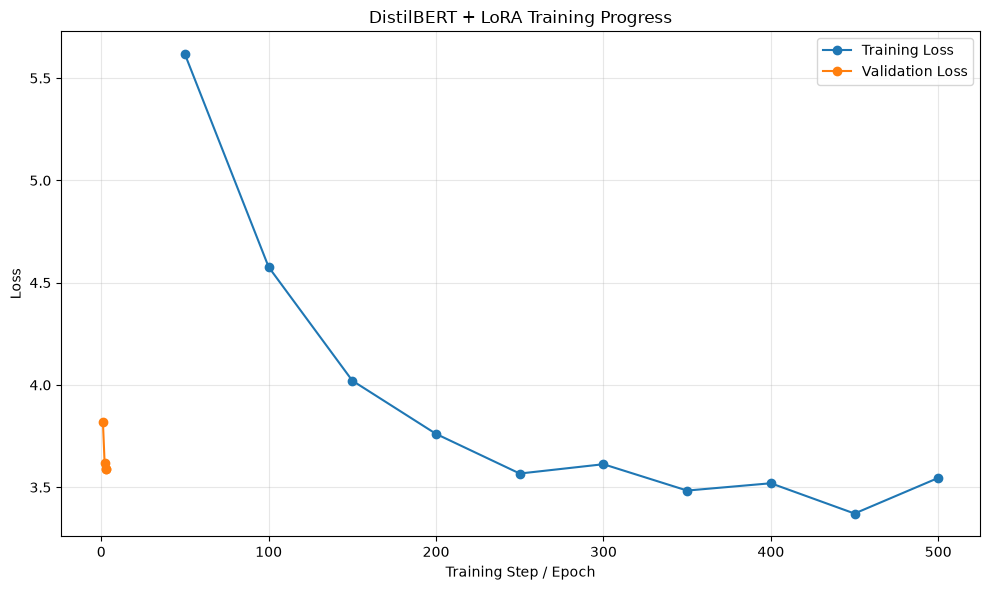

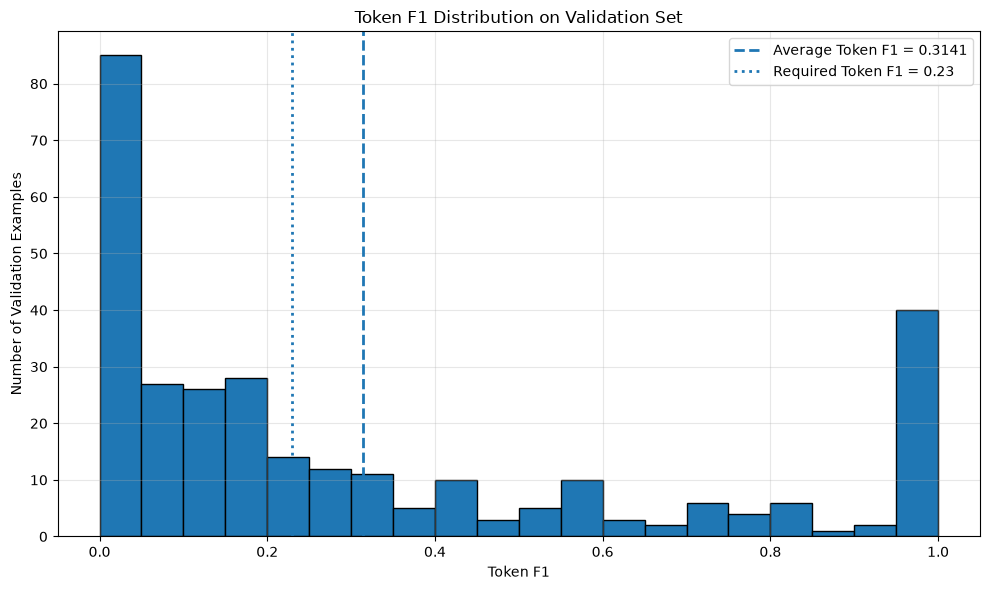

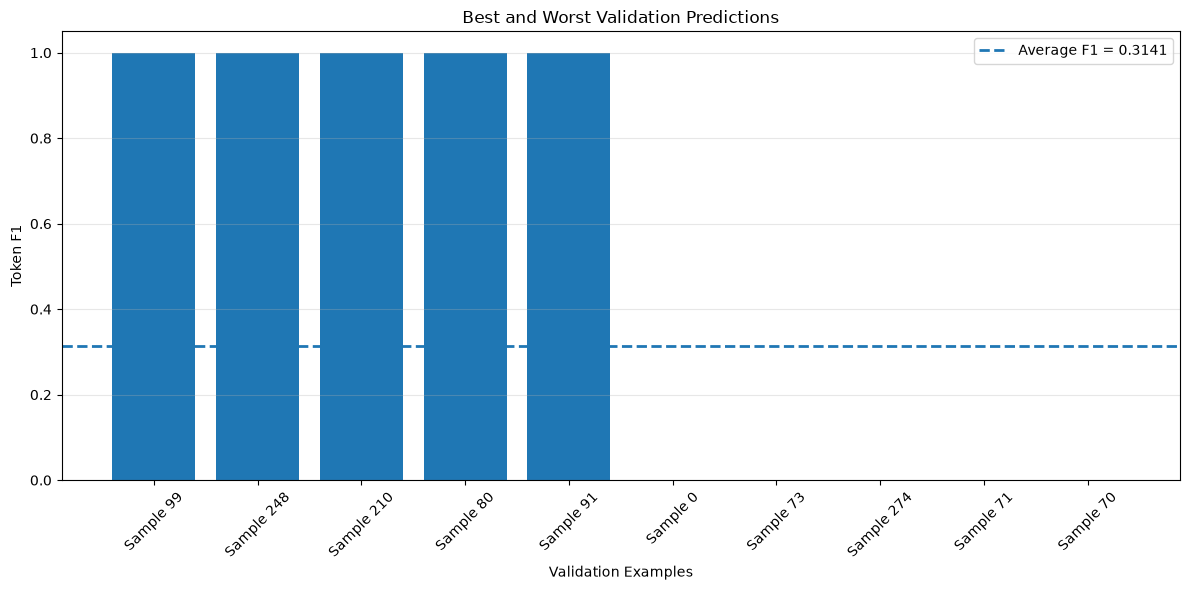

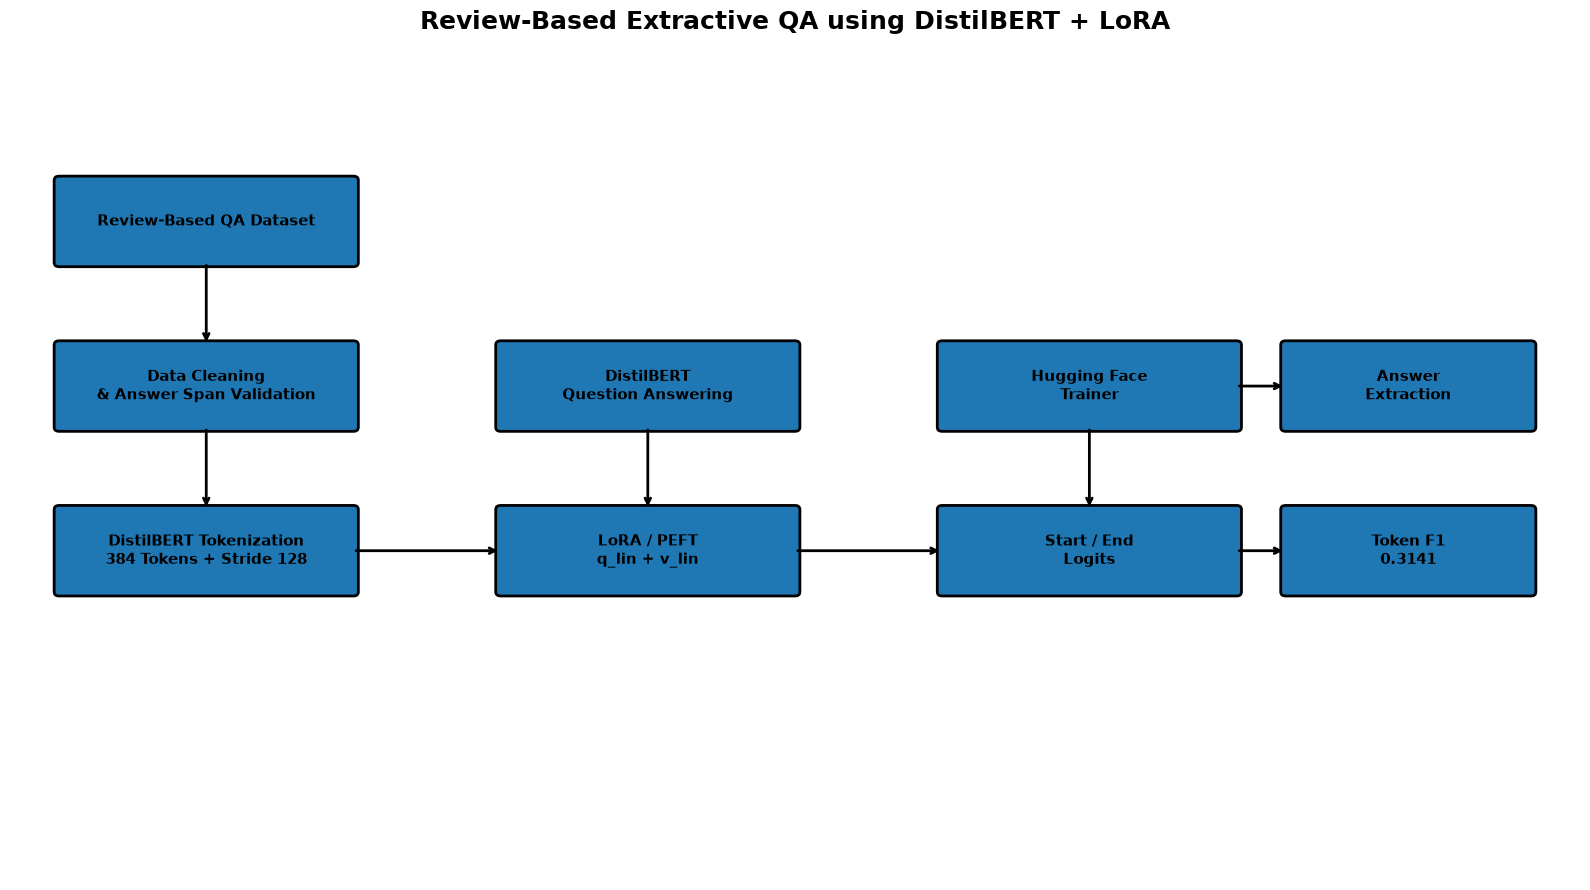


ALL VISUALIZATIONS SAVED
✓ images/project_architecture.png
✓ images/sample_prediction_f1.png
✓ images/token_f1_distribution.png
✓ images/training_validation_loss.png

Image directory:
/Users/ebbejulankapalli/Seq2Seq-Transformers-Transfer-Learning /Review-Based Extractive QA using Transfer Learning/images


In [55]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# ============================================================
# CREATE IMAGE DIRECTORY
# ============================================================

IMAGE_DIR = "images"
os.makedirs(IMAGE_DIR, exist_ok=True)

print("=" * 80)
print("GENERATING PROJECT VISUALIZATIONS")
print("=" * 80)


# ============================================================
# 1. TRAINING VS VALIDATION LOSS
# ============================================================

log_history = trainer_peft.state.log_history

train_steps = []
train_losses = []

eval_epochs = []
eval_losses = []

for log in log_history:

    if "loss" in log and "epoch" in log:
        train_steps.append(log.get("step", 0))
        train_losses.append(log["loss"])

    if "eval_loss" in log and "epoch" in log:
        eval_epochs.append(log["epoch"])
        eval_losses.append(log["eval_loss"])


plt.figure(figsize=(10, 6))

plt.plot(
    train_steps,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    eval_epochs,
    eval_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Training Step / Epoch")
plt.ylabel("Loss")
plt.title("DistilBERT + LoRA Training Progress")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        IMAGE_DIR,
        "training_validation_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 2. TOKEN F1 DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    f1_scores,
    bins=20,
    edgecolor="black"
)

plt.axvline(
    overall_token_f1,
    linestyle="--",
    linewidth=2,
    label=f"Average Token F1 = {overall_token_f1:.4f}"
)

plt.axvline(
    0.23,
    linestyle=":",
    linewidth=2,
    label="Required Token F1 = 0.23"
)

plt.xlabel("Token F1")
plt.ylabel("Number of Validation Examples")
plt.title("Token F1 Distribution on Validation Set")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        IMAGE_DIR,
        "token_f1_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 3. BEST AND WORST PREDICTION F1
# ============================================================

sorted_indices = np.argsort(f1_scores)

worst_indices = sorted_indices[:5]
best_indices = sorted_indices[-5:][::-1]

selected_indices = list(best_indices) + list(worst_indices)

labels = [
    f"Sample {i}"
    for i in selected_indices
]

scores = [
    f1_scores[i]
    for i in selected_indices
]

plt.figure(figsize=(12, 6))

plt.bar(
    labels,
    scores
)

plt.axhline(
    overall_token_f1,
    linestyle="--",
    linewidth=2,
    label=f"Average F1 = {overall_token_f1:.4f}"
)

plt.xlabel("Validation Examples")
plt.ylabel("Token F1")
plt.title("Best and Worst Validation Predictions")

plt.xticks(rotation=45)

plt.legend()
plt.grid(True, axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        IMAGE_DIR,
        "sample_prediction_f1.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 4. PROJECT ARCHITECTURE
# ============================================================

fig, ax = plt.subplots(figsize=(16, 9))

ax.set_xlim(0, 16)
ax.set_ylim(0, 10)
ax.axis("off")


boxes = [
    (
        0.5, 7.5, 3.0, 1.0,
        "Review-Based QA Dataset"
    ),
    (
        0.5, 5.5, 3.0, 1.0,
        "Data Cleaning\n& Answer Span Validation"
    ),
    (
        0.5, 3.5, 3.0, 1.0,
        "DistilBERT Tokenization\n384 Tokens + Stride 128"
    ),
    (
        5.0, 5.5, 3.0, 1.0,
        "DistilBERT\nQuestion Answering"
    ),
    (
        5.0, 3.5, 3.0, 1.0,
        "LoRA / PEFT\nq_lin + v_lin"
    ),
    (
        9.5, 5.5, 3.0, 1.0,
        "Hugging Face\nTrainer"
    ),
    (
        9.5, 3.5, 3.0, 1.0,
        "Start / End\nLogits"
    ),
    (
        13.0, 5.5, 2.5, 1.0,
        "Answer\nExtraction"
    ),
    (
        13.0, 3.5, 2.5, 1.0,
        "Token F1\n0.3141"
    )
]


for x, y, w, h, text in boxes:

    box = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.05",
        linewidth=2
    )

    ax.add_patch(box)

    ax.text(
        x + w / 2,
        y + h / 2,
        text,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )


arrows = [
    ((2.0, 7.5), (2.0, 6.5)),
    ((2.0, 5.5), (2.0, 4.5)),
    ((3.5, 4.0), (5.0, 4.0)),
    ((6.5, 5.5), (6.5, 4.5)),
    ((8.0, 4.0), (9.5, 4.0)),
    ((11.0, 5.5), (11.0, 4.5)),
    ((12.5, 4.0), (13.0, 4.0)),
    ((12.5, 6.0), (13.0, 6.0))
]


for start, end in arrows:

    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops=dict(
            arrowstyle="->",
            linewidth=2
        )
    )


ax.set_title(
    "Review-Based Extractive QA using DistilBERT + LoRA",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        IMAGE_DIR,
        "project_architecture.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)
print("ALL VISUALIZATIONS SAVED")
print("=" * 80)

for filename in sorted(os.listdir(IMAGE_DIR)):
    print("✓", os.path.join(IMAGE_DIR, filename))

print("\nImage directory:")
print(os.path.abspath(IMAGE_DIR))

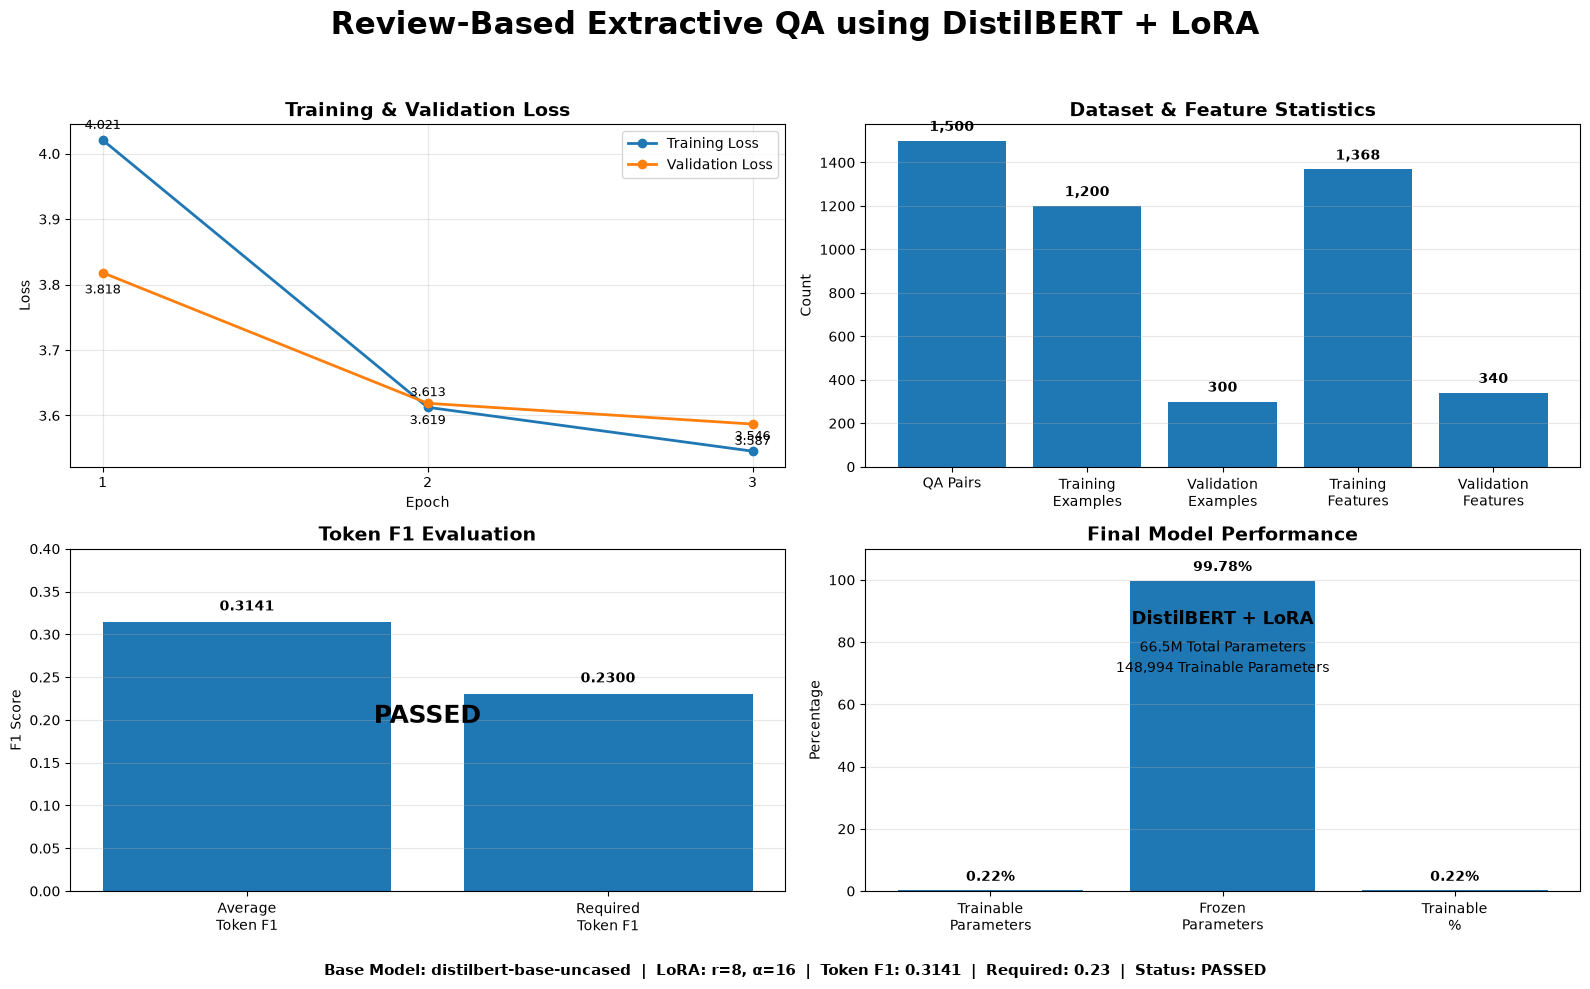

PROJECT DASHBOARD CREATED
Saved to:
/Users/ebbejulankapalli/Seq2Seq-Transformers-Transfer-Learning /Review-Based Extractive QA using Transfer Learning/images/review_qa_project_dashboard.png


In [56]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# REVIEW-BASED EXTRACTIVE QA - PROJECT DASHBOARD
# ============================================================

IMAGE_DIR = "images"
os.makedirs(IMAGE_DIR, exist_ok=True)

# ------------------------------------------------------------
# Actual project results
# ------------------------------------------------------------

epochs = [1, 2, 3]

training_losses = [
    4.020839,
    3.612528,
    3.545508
]

validation_losses = [
    3.818151,
    3.618654,
    3.586906
]

total_qa_pairs = 1500
training_examples = 1200
validation_examples = 300

training_features = 1368
validation_features = 340

trainable_params = 148994
total_params = 66513412
trainable_percentage = 0.2240

token_f1 = overall_token_f1
required_f1 = 0.23

# Number of validation examples by F1 quality
f1_scores_array = np.array(f1_scores)

excellent = np.sum(f1_scores_array >= 0.70)
good = np.sum(
    (f1_scores_array >= 0.40) &
    (f1_scores_array < 0.70)
)
partial = np.sum(
    (f1_scores_array >= 0.23) &
    (f1_scores_array < 0.40)
)
low = np.sum(f1_scores_array < 0.23)

# ------------------------------------------------------------
# Create dashboard
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10)
)

fig.suptitle(
    "Review-Based Extractive QA using DistilBERT + LoRA",
    fontsize=22,
    fontweight="bold"
)


# ============================================================
# TOP LEFT — TRAINING LOSS
# ============================================================

ax = axes[0, 0]

ax.plot(
    epochs,
    training_losses,
    marker="o",
    linewidth=2,
    label="Training Loss"
)

ax.plot(
    epochs,
    validation_losses,
    marker="o",
    linewidth=2,
    label="Validation Loss"
)

ax.set_title(
    "Training & Validation Loss",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")

ax.set_xticks(epochs)

ax.grid(
    True,
    alpha=0.3
)

ax.legend()

# Add values
for x, y in zip(epochs, training_losses):
    ax.annotate(
        f"{y:.3f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9
    )

for x, y in zip(epochs, validation_losses):
    ax.annotate(
        f"{y:.3f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, -15),
        ha="center",
        fontsize=9
    )


# ============================================================
# TOP RIGHT — DATASET / FEATURE STATISTICS
# ============================================================

ax = axes[0, 1]

dataset_labels = [
    "QA Pairs",
    "Training\nExamples",
    "Validation\nExamples",
    "Training\nFeatures",
    "Validation\nFeatures"
]

dataset_values = [
    total_qa_pairs,
    training_examples,
    validation_examples,
    training_features,
    validation_features
]

bars = ax.bar(
    dataset_labels,
    dataset_values
)

ax.set_title(
    "Dataset & Feature Statistics",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Count")

ax.grid(
    True,
    axis="y",
    alpha=0.3
)

for bar, value in zip(bars, dataset_values):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(dataset_values) * 0.02,
        f"{value:,}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )


# ============================================================
# BOTTOM LEFT — TOKEN F1
# ============================================================

ax = axes[1, 0]

f1_labels = [
    "Average\nToken F1",
    "Required\nToken F1"
]

f1_values = [
    token_f1,
    required_f1
]

bars = ax.bar(
    f1_labels,
    f1_values
)

ax.set_title(
    "Token F1 Evaluation",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("F1 Score")

ax.set_ylim(
    0,
    max(0.4, token_f1 + 0.08)
)

ax.grid(
    True,
    axis="y",
    alpha=0.3
)

for bar, value in zip(bars, f1_values):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

# Pass label
ax.text(
    0.5,
    max(f1_values) * 0.65,
    "PASSED",
    ha="center",
    va="center",
    fontsize=18,
    fontweight="bold"
)


# ============================================================
# BOTTOM RIGHT — FINAL MODEL PERFORMANCE
# ============================================================

ax = axes[1, 1]

performance_labels = [
    "Trainable\nParameters",
    "Frozen\nParameters",
    "Trainable\n%"
]

frozen_percentage = (
    100 - trainable_percentage
)

performance_values = [
    trainable_params / total_params * 100,
    frozen_percentage,
    trainable_percentage
]

bars = ax.bar(
    performance_labels,
    performance_values
)

ax.set_title(
    "Final Model Performance",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Percentage")

ax.set_ylim(
    0,
    110
)

ax.grid(
    True,
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    performance_values
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

# Add model information
ax.text(
    0.5,
    0.78,
    "DistilBERT + LoRA",
    transform=ax.transAxes,
    ha="center",
    fontsize=13,
    fontweight="bold"
)

ax.text(
    0.5,
    0.70,
    "66.5M Total Parameters",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)

ax.text(
    0.5,
    0.64,
    "148,994 Trainable Parameters",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)


# ============================================================
# FOOTER
# ============================================================

fig.text(
    0.5,
    0.015,
    (
        f"Base Model: distilbert-base-uncased  |  "
        f"LoRA: r=8, α=16  |  "
        f"Token F1: {token_f1:.4f}  |  "
        f"Required: {required_f1:.2f}  |  "
        f"Status: PASSED"
    ),
    ha="center",
    fontsize=11,
    fontweight="bold"
)


# ============================================================
# SAVE
# ============================================================

plt.tight_layout(
    rect=[0, 0.04, 1, 0.95]
)

output_path = os.path.join(
    IMAGE_DIR,
    "review_qa_project_dashboard.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


print("=" * 80)
print("PROJECT DASHBOARD CREATED")
print("=" * 80)
print("Saved to:")
print(os.path.abspath(output_path))
print("=" * 80)